# Track 3 — Semiconductor Wafer Quality & Fault Detection

**Goal:** classify wafer inspection outcomes (`target=0` pass, `target=1` fail).  
**Evaluation:** Balanced Accuracy and PR-AUC (Average Precision).  
**Dataset note:** this notebook uses the advanced-track `train.csv` included in this folder. The other uploaded `train.csv` in the original conversation was the Beginner machine-failure dataset.

Run all cells from top to bottom. The notebook saves `cleaned_dataset.csv`, `model.joblib`, `validation_metrics.json`, and `predict.py`.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    balanced_accuracy_score, average_precision_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report,
    precision_recall_curve
)

RANDOM_STATE = 42
DATA_PATH = Path("train.csv")
OUTPUT_DIR = Path(".")

## 1. Load and inspect the data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print("\\nColumns:", len(df.columns))
print("Target counts:")
display(df["target"].value_counts(dropna=False).rename(index={0: "Pass (0)", 1: "Fail (1)"}))
print("Target rate:", df["target"].mean())

Shape: (1253, 592)


,timestamp,target,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_580,sensor_581,sensor_582,sensor_583,sensor_584,sensor_585,sensor_586,sensor_587,sensor_588,sensor_589
0,24/08/2008 07:14:00,0,2882.17,2601.98,2213.9333,1248.6209,1.8848,100.0,97.1856,0.1209,...,NaN,NaN,0.5090,0.0168,0.0048,3.2968,0.0282,0.0194,0.0059,68.7444
1,06/10/2008 15:00:00,1,2988.39,2493.72,2206.4000,982.5452,1.1853,100.0,116.8167,0.1228,...,0.0039,0.0000,0.4972,0.0154,0.0035,3.0992,-0.0006,0.0118,0.0039,0.0000
2,17/10/2008 05:26:00,0,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,...,0.0025,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231
3,18/08/2008 17:16:00,0,3038.25,2337.96,2244.1111,1676.7316,0.9197,100.0,100.8067,0.1204,...,NaN,NaN,0.5033,0.0157,0.0042,3.1246,0.0274,0.0142,0.0046,51.9067
4,07/10/2008 19:24:00,0,2985.78,2460.97,2200.2111,1048.3108,1.6485,100.0,98.3222,0.1214,...,NaN,NaN,0.4963,0.0138,0.0040,2.7888,0.0458,0.0277,0.0100,60.5430


\nColumns: 592
Target counts:


target
Pass (0)    1170
Fail (1)      83
Name: count, dtype: int64

Target rate: 0.06624102154828412


## 2. Missingness and class imbalance

Sensor features: 590
Missing sensor cells: 33,940 / 739,270 (4.59%)
Pass count: 1,170; fail count: 83; fail rate: 6.62%


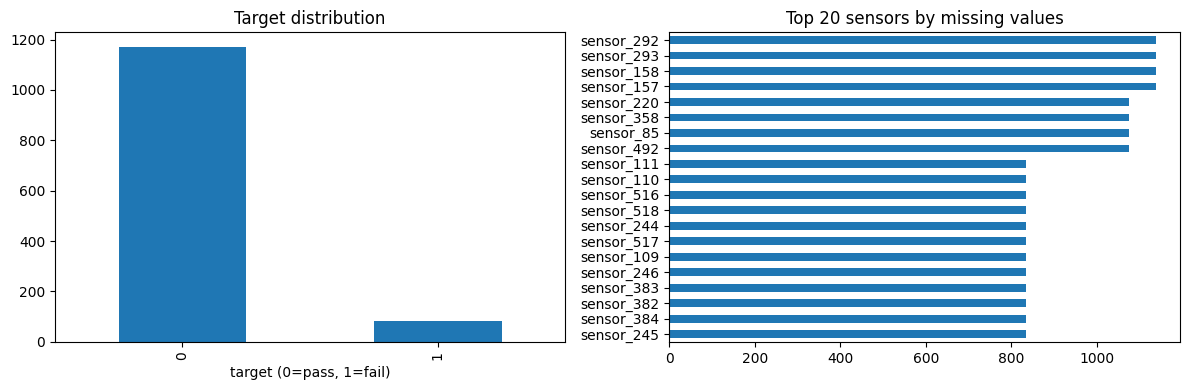

Schema check: sensor range in uploaded data is sensor_0 to sensor_589
The problem statement mentions sensor_590, but the uploaded file contains 590 sensor columns.


In [3]:
target_col = "target"
timestamp_col = "timestamp"
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]

X = df[sensor_cols].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(df[target_col], errors="raise").astype(int)

missing = X.isna().sum().sort_values(ascending=False)
print(f"Sensor features: {len(sensor_cols)}")
print(f"Missing sensor cells: {int(X.isna().sum().sum()):,} / {X.size:,} ({X.isna().sum().sum()/X.size:.2%})")
print(f"Pass count: {(y == 0).sum():,}; fail count: {(y == 1).sum():,}; fail rate: {y.mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Target distribution")
axes[0].set_xlabel("target (0=pass, 1=fail)")
missing.head(20).sort_values().plot(kind="barh", ax=axes[1], title="Top 20 sensors by missing values")
plt.tight_layout()
plt.show()

print("Schema check: sensor range in uploaded data is", sensor_cols[0], "to", sensor_cols[-1])
print("The problem statement mentions sensor_590, but the uploaded file contains", len(sensor_cols), "sensor columns.")

## 3. Holdout split and model pipeline

A stratified 75/25 holdout keeps the minority class represented in both partitions. Median imputation and zero-variance feature filtering are inside the pipeline so they are fitted on training folds only. Class-balanced weights reduce the effect of target imbalance without duplicating observations.

In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

def build_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("variance", VarianceThreshold(threshold=0.0)),
        ("classifier", ExtraTreesClassifier(
            n_estimators=500,
            max_features="sqrt",
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

model = build_model()
model.fit(X_train, y_train)
print("Train rows:", len(X_train), "Validation rows:", len(X_valid))
print("Features retained after variance filtering:", model.named_steps["variance"].get_support().sum())

Train rows: 939 Validation rows: 314
Features retained after variance filtering: 474


## 4. Select a threshold using training-only out-of-fold predictions

The default 0.5 threshold may miss minority-class cases. Select a threshold from 5-fold stratified out-of-fold predictions on the training partition. The holdout is not used to select the threshold. PR-AUC is calculated from probabilities and is independent of the classification threshold.

In [5]:
oof_prob = cross_val_predict(
    build_model(), X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba", n_jobs=1
)[:, 1]

precision_oof, recall_oof, thresholds_oof = precision_recall_curve(y_train, oof_prob)
threshold_candidates = np.unique(np.concatenate(([0.0], thresholds_oof, [1.0])))
selected_threshold = max(
    threshold_candidates,
    key=lambda t: balanced_accuracy_score(y_train, oof_prob >= t)
)
print("Selected threshold:", round(float(selected_threshold), 4))
print("Training OOF Balanced Accuracy at threshold:",
      round(balanced_accuracy_score(y_train, oof_prob >= selected_threshold), 4))
print("Training OOF PR-AUC:", round(average_precision_score(y_train, oof_prob), 4))

Selected threshold: 0.052
Training OOF Balanced Accuracy at threshold: 0.6909
Training OOF PR-AUC: 0.1632


## 5. Evaluate on the untouched holdout

In [6]:
valid_prob = model.predict_proba(X_valid)[:, 1]
valid_pred = (valid_prob >= selected_threshold).astype(int)

metrics = {
    "validation_rows": int(len(y_valid)),
    "pr_auc_average_precision": float(average_precision_score(y_valid, valid_prob)),
    "balanced_accuracy": float(balanced_accuracy_score(y_valid, valid_pred)),
    "precision_defective": float(precision_score(y_valid, valid_pred, zero_division=0)),
    "recall_defective": float(recall_score(y_valid, valid_pred, zero_division=0)),
    "f1_defective": float(f1_score(y_valid, valid_pred, zero_division=0)),
    "selected_threshold": float(selected_threshold),
    "confusion_matrix_tn_fp_fn_tp": confusion_matrix(y_valid, valid_pred).ravel().tolist()
}
display(pd.DataFrame([metrics]).T.rename(columns={0: "Value"}))
print(classification_report(y_valid, valid_pred, zero_division=0))
print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_valid, valid_pred))

,Value
validation_rows,314
pr_auc_average_precision,0.197345
balanced_accuracy,0.616447
precision_defective,0.093567
recall_defective,0.761905
f1_defective,0.166667
selected_threshold,0.052
confusion_matrix_tn_fp_fn_tp,"[138, 155, 5, 16]"


              precision    recall  f1-score   support

           0       0.97      0.47      0.63       293
           1       0.09      0.76      0.17        21

    accuracy                           0.49       314
   macro avg       0.53      0.62      0.40       314
weighted avg       0.91      0.49      0.60       314

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[138 155]
 [  5  16]]


## 6. Save a cleaned dataset

This is a convenience copy for inspection. The actual model pipeline still performs imputation internally, which is the preferred approach for avoiding validation leakage.

In [7]:
cleaner = SimpleImputer(strategy="median", keep_empty_features=True)
clean_values = cleaner.fit_transform(X)
clean_df = pd.DataFrame(clean_values, columns=sensor_cols)
clean_df.insert(0, "target", y.values)
if timestamp_col in df.columns:
    clean_df.insert(0, "timestamp", df[timestamp_col].values)
clean_df.to_csv("cleaned_dataset.csv", index=False)
print("Saved cleaned_dataset.csv", clean_df.shape)

Saved cleaned_dataset.csv (1253, 592)


## 7. Fit final model on all labelled data and save artifact

After local evaluation, train the final inference pipeline on all labelled rows. The local holdout metrics above remain the reportable validation estimate; the full-data fit is the artifact used for inference.

In [8]:
final_model = build_model()
final_model.fit(X, y)

bundle = {
    "model": final_model,
    "sensor_columns": sensor_cols,
    "threshold": float(selected_threshold),
    "target_column": target_col,
    "timestamp_column": timestamp_col,
    "model_name": "ExtraTreesClassifier with median imputation and variance filtering"
}
joblib.dump(bundle, "model.joblib")
metrics["sensor_columns_used"] = int(len(sensor_cols))
metrics["positive_count_total"] = int((y == 1).sum())
metrics["negative_count_total"] = int((y == 0).sum())
metrics["missing_sensor_fraction"] = float(X.isna().sum().sum() / X.size)
with open("validation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print("Saved model.joblib and validation_metrics.json")

Saved model.joblib and validation_metrics.json


## 8. Inference function

Input data must contain sensor readings. `timestamp` is optional; `target` is not required. Missing expected sensor columns are created as missing values and handled by the saved imputer. Extra columns are ignored.

In [9]:
def predict_dataframe(input_df, bundle_path="model.joblib"):
    bundle = joblib.load(bundle_path)
    sensor_columns = bundle["sensor_columns"]
    for col in sensor_columns:
        if col not in input_df.columns:
            input_df[col] = np.nan
    X_new = input_df[sensor_columns].apply(pd.to_numeric, errors="coerce")
    probabilities = bundle["model"].predict_proba(X_new)[:, 1]
    labels = (probabilities >= bundle["threshold"]).astype(int)
    result = pd.DataFrame({
        "predicted_target": labels,
        "defect_probability": probabilities
    })
    if "timestamp" in input_df.columns:
        result.insert(0, "timestamp", input_df["timestamp"].values)
    return result
    
sample = df.drop(columns=["target"]).head(5).copy()
display(predict_dataframe(sample))

,timestamp,predicted_target,defect_probability
0,24/08/2008 07:14:00,0,0.0
1,06/10/2008 15:00:00,1,1.0
2,17/10/2008 05:26:00,0,0.0
3,18/08/2008 17:16:00,0,0.0
4,07/10/2008 19:24:00,0,0.0


## Findings and limitations

- The uploaded dataset is small relative to its sensor count and has a severe minority class.
- Missing-value handling and variance filtering are included in the reproducible pipeline.
- Threshold selection affects the precision/recall trade-off; false positives and false negatives should be discussed with process engineers.
- The scores above are local validation scores, not the organizers' hidden-test scores. A single split can vary, so repeated stratified validation and further model comparisons are recommended.
- The statement describes 591 sensors (`sensor_0`–`sensor_590`), but this uploaded file contains 590 (`sensor_0`–`sensor_589`). Confirm with organizers if they expect a different schema.